### Shared subspace and proficiency probes with continuous 1 FPS video windows

The midterm representation analysis (`midterm/idea_1_midterm_representation.ipynb`) embedded each video from
16 frames spread uniformly over the whole clip, the sampling checkpoint 50 was fine-tuned with. Here each
video is instead a **contiguous window sampled at 1 FPS**: up to `MAX_FRAMES` consecutive seconds, starting at a
random point in the clip (seeded by the take name, so every run and both models see the same window). Clips
shorter than the window are taken whole at 1 FPS. Frames are kept at the full 448x448 the model was trained on.

Everything else is unchanged from the midterm: the video is fed alone in a user turn and mean-pooled over the
video tokens at every decoder layer, for the fine-tuned model (LoRA checkpoint 50) and the zero-shot base model;
the commentary embeddings don't depend on the video, so they are reused from the midterm cache. CCA (on PCA-128
per modality, fit on train) gives the shared video/commentary subspace, and logistic-regression probes compare
proficiency information in the full, shared and residual video embeddings against the PCA and random-subspace
controls. The midterm's uniform 16-frame embeddings go through the same pipeline alongside, for comparison.

In [1]:
import json
import re
from pathlib import Path

# Same data layout and preprocessing as midterm/idea_1_midterm_representation.ipynb.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}
VIDEO_TYPE = "ego"  # the view checkpoint 50 was fine-tuned on

# The commentary the model was trained on had the rating terms masked out; keep that.
RATING_TERMS = re.compile(
    r"\b(?:novice|early\s+expert|intermediate\s+expert|late\s+expert|"
    r"proficien\w*|rating|score|good\s+execution|tip\s+for\s+improvement|beginner)\b",
    flags=re.IGNORECASE,
)

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m, video_type):
    parts = m["video_paths"][video_type].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def load_commentary(take):
    """The take's expert commentary in the training format (one block per expert), or None."""
    experts = []
    for data_path in sorted((COMMENTARY_ROOT / take).rglob("data.json")):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        segments = []
        for annotation in data.get("annotations", []):
            text = transcripts.get(annotation.get("recording_path"), {}).get("text", "").strip()
            if text:
                segments.append((annotation.get("video_time") or 0.0, RATING_TERMS.sub("[MASK]", text)))
        if segments:
            lines = "\n".join(f"[{t:.1f}s] {text}" for t, text in sorted(segments))
            experts.append(f"Expert {len(experts) + 1}:\n{lines}")
    if not experts:
        return None
    return "\n\n".join(experts)


with open("SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    """Takes with both a video and commentary. "train" is every train take; "test" is the val takes
    listed in SkillFormer/annotation_test.jsonl -- the same takes evaluate() scores in the midterm notebook."""
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m, VIDEO_TYPE).exists():
            continue
        commentary = load_commentary(take_name(m))
        if commentary is None:
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"],
                      "score": LEVELS[m["proficiency_score"]], "video": str(video_path(m, VIDEO_TYPE)),
                      "commentary": commentary})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} clips with video and commentary")

train: 1174 clips with video and commentary
test: 164 clips with video and commentary


In [2]:
import zlib

import numpy as np
import torch
from peft import PeftModel
from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
from transformers.video_utils import load_video

model_id = "Qwen/Qwen3.5-4B"
CHECKPOINT = "./qwen35-4b-finetuned/checkpoint-50"
WINDOW_FPS = 1
# Most frames per window that fit on the 12 GB GPU at 448x448: 160 frames (15.7k video tokens) peak at 8.7 GiB
# for a video-only forward pass; 176 run out of memory.
MAX_FRAMES = 160

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)
base_model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto")
model = PeftModel.from_pretrained(base_model, CHECKPOINT).eval()
processor = AutoProcessor.from_pretrained(model_id)

# torchcodec can't load on this machine; decode with PyAV (see idea_1_midterm.ipynb).
def fetch_videos_pyav(video_url_or_urls, sample_indices_fn=None):
    if isinstance(video_url_or_urls, list):
        return list(zip(*[fetch_videos_pyav(x, sample_indices_fn) for x in video_url_or_urls]))
    return load_video(video_url_or_urls, backend="pyav", sample_indices_fn=sample_indices_fn)

processor.video_processor.fetch_videos = fetch_videos_pyav
processor.video_processor.fps = None
# The processor's pixel budget (size["longest_edge"]) would shrink frames below 448x448 past ~124 frames;
# lift it so every frame keeps the resolution the model was fine-tuned on.
processor.video_processor.size = {"shortest_edge": processor.video_processor.size.shortest_edge, "longest_edge": 10**12}
processor.video_processor.cap_pixels_per_frame = False

_window_rng, _window = None, None  # the clip's RNG while it is being loaded, and the window that was sampled

def continuous_window(metadata, **kwargs):
    """Frame indices of a contiguous WINDOW_FPS window at a random start: MAX_FRAMES frames, or every 1 FPS frame
    of a shorter clip. Always an even count, since the vision encoder patches frames in pairs."""
    global _window
    step = round(metadata.fps / WINDOW_FPS)
    available = (metadata.total_num_frames - 1) // step + 1
    num_frames = min(MAX_FRAMES, available - available % 2)
    start = int(_window_rng.integers(0, metadata.total_num_frames - (num_frames - 1) * step))
    _window = {"start_s": start / metadata.fps, "num_frames": num_frames, "clip_s": metadata.total_num_frames / metadata.fps}
    return start + step * np.arange(num_frames)

# Replaces the uniform sampling; the processor calls it with the decoded video's metadata.
processor.video_processor.sample_frames = continuous_window

VIDEO_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids("<|video_pad|>")

W1111 19:19:51.644000 2332 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

In [3]:
# Mean-pool every decoder layer's output inside a forward hook, so the full (seq_len, 2560) hidden
# states of all 32 layers never have to be kept around. Layer k's entry is the residual stream after
# decoder layer k (1-indexed); the last one is taken before the final RMSNorm, like the others.
DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
assert len(DECODER_LAYERS) == base_model.config.text_config.num_hidden_layers

_pool_mask, _pooled = None, []

def _pool_hook(module, args, output):
    if _pool_mask is None:
        return
    hidden = output[0] if isinstance(output, tuple) else output
    _pooled.append(hidden[0, _pool_mask].float().mean(0).cpu())

for layer in DECODER_LAYERS:
    layer.register_forward_hook(_pool_hook)

@torch.inference_mode()
def layer_means(batch, mask):
    """(num_layers, hidden) mean of each decoder layer's output over the positions where mask is True."""
    global _pool_mask
    assert mask.any(), "nothing to pool over"
    _pool_mask = mask.to(model.device)
    _pooled.clear()
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16):  # training and evaluation ran under bf16 autocast
            model(**batch.to(model.device), logits_to_keep=1)
    finally:
        _pool_mask = None
    return torch.stack(_pooled)

def video_embeddings(clip):
    """The clip's 1 FPS window alone, no text, pooled over the video tokens: {"checkpoint-50": ..., "base": ...,
    plus the window}. Both models see the same decoded frames."""
    global _window_rng
    _window_rng = np.random.default_rng(zlib.crc32(clip["take_name"].encode()))
    batch = processor.apply_chat_template(
        [{"role": "user", "content": [{"type": "video", "video": clip["video"]}]}],
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    t, h, w = batch["video_grid_thw"][0].tolist()
    assert 2 * t == _window["num_frames"] and (h, w) == (28, 28), (batch["video_grid_thw"], _window)
    mask = batch["input_ids"][0] == VIDEO_TOKEN_ID
    embeddings = {Path(CHECKPOINT).name: layer_means(batch, mask)}
    with model.disable_adapter():
        embeddings["base"] = layer_means(batch, mask)
    return {**embeddings, **_window}

In [4]:
import functools

from tqdm.auto import tqdm

# Raw (uncentered) per-layer means for every clip, cached per split so an interrupted run resumes.
EMBEDDING_DIR = Path("embeddings")
EMBEDDING_DIR.mkdir(exist_ok=True)
MODEL_NAMES = {Path(CHECKPOINT).name: "Fine-tuned", "base": "Zero-shot"}

def embed_split(split):
    """{take name: video_embeddings(clip)} for every clip of the split; video embeddings are (32 layers, 2560)."""
    split_list = clips_by_split[split]
    raw_path = EMBEDDING_DIR / f"qwen35_continuous{WINDOW_FPS}fps{MAX_FRAMES}_{split}_raw.pt"
    raw = torch.load(raw_path) if raw_path.exists() else {}
    todo = [clip for clip in split_list if clip["take_name"] not in raw]
    print(f"{split}: {len(split_list) - len(todo)} clips already embedded, {len(todo)} to go")
    for k, clip in enumerate(tqdm(todo), 1):
        raw[clip["take_name"]] = video_embeddings(clip)
        if k % 25 == 0:
            torch.save(raw, raw_path)
    torch.save(raw, raw_path)
    return raw

continuous_raw = {split: embed_split(split) for split in ("test", "train")}

@functools.cache
def midterm_raw(split, model_name):
    return torch.load(EMBEDDING_DIR / f"qwen35_{model_name}_{split}_raw.pt")

def paired(split, model_name, video_source):
    """(video, text) raw embeddings of the split's clips, each (clips, 32 layers, 2560). The commentary embeddings
    come from the midterm cache: they don't depend on how the video is sampled."""
    midterm = midterm_raw(split, model_name)
    takes = [clip["take_name"] for clip in clips_by_split[split]]
    video = continuous_raw[split] if video_source == "continuous" else midterm
    return torch.stack([video[t][model_name if video_source == "continuous" else "video"] for t in takes]), \
           torch.stack([midterm[t]["text"] for t in takes])

# {(sampling, model name): {split: (video, text)}}; "uniform" is the midterm's 16 frames over the whole clip.
SAMPLINGS = {"uniform": "Uniform 16", "continuous": f"Continuous {WINDOW_FPS} FPS"}
raw_embeddings = {(sampling, model_name): {split: paired(split, model_name, sampling) for split in ("test", "train")}
                  for sampling in SAMPLINGS for model_name in MODEL_NAMES}
midterm_raw.cache_clear()
for key, splits in raw_embeddings.items():
    print(key, {split: tuple(video.shape) for split, (video, _) in splits.items()})

test: 0 clips already embedded, 164 to go


  0%|          | 0/164 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


train: 0 clips already embedded, 1174 to go


  0%|          | 0/1174 [00:00<?, ?it/s]

('uniform', 'checkpoint-50') {'test': (164, 32, 2560), 'train': (1174, 32, 2560)}
('uniform', 'base') {'test': (164, 32, 2560), 'train': (1174, 32, 2560)}
('continuous', 'checkpoint-50') {'test': (164, 32, 2560), 'train': (1174, 32, 2560)}
('continuous', 'base') {'test': (164, 32, 2560), 'train': (1174, 32, 2560)}


In [5]:
# How much of each clip the windows cover.
for split in ("train", "test"):
    windows = [continuous_raw[split][clip["take_name"]] for clip in clips_by_split[split]]
    frames = np.array([w["num_frames"] for w in windows])
    coverage = np.array([w["num_frames"] / WINDOW_FPS / w["clip_s"] for w in windows]).clip(max=1)
    print(f"{split}: {(frames == MAX_FRAMES).mean():.0%} of clips get the full {MAX_FRAMES}-frame window; "
          f"frames per clip min/median/max {frames.min()}/{int(np.median(frames))}/{frames.max()}; "
          f"median coverage of the clip {np.median(coverage):.0%}, {(coverage >= 0.95).mean():.0%} of clips >= 95% covered")

train: 18% of clips get the full 160-frame window; frames per clip min/median/max 4/56/160; median coverage of the clip 99%, 80% of clips >= 95% covered
test: 21% of clips get the full 160-frame window; frames per clip min/median/max 8/57/160; median coverage of the clip 99%, 79% of clips >= 95% covered


#### Shared subspace (CCA)

As in the midterm: each modality is reduced with PCA-128 (fit on train), CCA is fit on the train pairs and
scored on the held-out test pairs, with a permutation floor from shuffled test pairs and each component's
scenario eta² (share of its test variance that lies between scenarios). Layer 31 is dropped: the midterm only
needed it for the forward-pass interventions.

In [6]:
from sklearn.cross_decomposition import CCA
from sklearn.decomposition import PCA

LAYERS = {"early": 8, "middle": 16, "last": 32}
N_COMPONENTS = 32
PCA_DIMS = 128  # per modality, before CCA; exact SVD so reruns give identical results
N_PERMUTATIONS = 1000

def canonical_correlations(video_shared, text_shared):
    """Pearson correlation between each pair of canonical variates (one per component)."""
    v = video_shared - video_shared.mean(0)
    t = text_shared - text_shared.mean(0)
    return (v * t).sum(0) / np.sqrt((v ** 2).sum(0) * (t ** 2).sum(0))

def scenario_eta2(shared, scenarios):
    """Share of each canonical variate's variance that lies between scenarios (1 = pure scenario identity)."""
    within = sum(((shared[scenarios == s] - shared[scenarios == s].mean(0)) ** 2).sum(0) for s in np.unique(scenarios))
    return 1 - within / ((shared - shared.mean(0)) ** 2).sum(0)

test_scenarios = np.array([clip["scenario"] for clip in clips])

def fit_cca(raw_embeddings):
    """PCA + CCA on the train pairs at each layer in LAYERS, scored on the test pairs; prints a summary."""
    train_video_all, train_text_all = raw_embeddings["train"]
    video_all, text_all = raw_embeddings["test"]
    rng = np.random.default_rng(0)
    results = {}
    for name, layer in LAYERS.items():
        V_train = train_video_all[:, layer - 1].double().numpy()
        T_train = train_text_all[:, layer - 1].double().numpy()
        V_test = video_all[:, layer - 1].double().numpy()
        T_test = text_all[:, layer - 1].double().numpy()

        pca_video = PCA(PCA_DIMS, svd_solver="full").fit(V_train)
        pca_text = PCA(PCA_DIMS, svd_solver="full").fit(T_train)
        cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(pca_video.transform(V_train), pca_text.transform(T_train))
        V_shared, T_shared = cca.transform(pca_video.transform(V_test), pca_text.transform(T_test))
        V_shared_train, T_shared_train = cca.transform(pca_video.transform(V_train), pca_text.transform(T_train))

        # The video canonical variates are affine in the embedding, u = (v - pca mean) @ directions + offset, so
        # the span of `directions` is the shared subspace in the model's 2560-d hidden-state space.
        directions = pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None])
        offset = -(cca._x_mean / cca._x_std) @ cca.x_rotations_
        assert np.allclose((V_test - pca_video.mean_) @ directions + offset, V_shared, atol=1e-6)

        test_corr = canonical_correlations(V_shared, T_shared)
        null = np.stack([canonical_correlations(V_shared, T_shared[rng.permutation(len(T_shared))])
                         for _ in range(N_PERMUTATIONS)])
        results[name] = {
            "layer": layer, "pca_video": pca_video, "pca_text": pca_text, "cca": cca,
            "mean": pca_video.mean_,  # train mean of the video embeddings
            "basis": np.linalg.qr(directions)[0],  # orthonormal (2560, N_COMPONENTS) basis of the shared subspace
            "V_shared": V_shared, "T_shared": T_shared,  # test clips projected onto the shared directions
            "train_corr": canonical_correlations(V_shared_train, T_shared_train),
            "test_corr": test_corr,
            "null_95": np.quantile(null, 0.95, axis=0),  # one-sided: 95th percentile of shuffled-pair correlations
            "scenario_eta2": scenario_eta2(V_shared, test_scenarios),
        }
        above = int((test_corr > results[name]["null_95"]).sum())
        print(f"  {name} (layer {layer}): {above}/{N_COMPONENTS} components above the permutation 95th percentile, "
              f"mean test r {test_corr.mean():.3f}")
        print("    component       " + "".join(f"{k:>6}" for k in range(1, 11)))
        print("    test r          " + "".join(f"{r:>6.2f}" for r in test_corr[:10]))
        print("    scenario eta2   " + "".join(f"{e:>6.2f}" for e in results[name]["scenario_eta2"][:10]))
    return results

cca_results = {}
for (sampling, model_name), embeddings in raw_embeddings.items():
    print(f"{SAMPLINGS[sampling]}, {MODEL_NAMES[model_name]}")
    cca_results[sampling, model_name] = fit_cca(embeddings)

Uniform 16, Fine-tuned


  early (layer 8): 30/32 components above the permutation 95th percentile, mean test r 0.576
    component            1     2     3     4     5     6     7     8     9    10
    test r            1.00  0.99  0.99  0.99  0.97  0.91  0.92  0.92  0.87  0.83
    scenario eta2     0.99  0.99  0.99  0.98  0.95  0.05  0.01  0.01  0.04  0.04


  middle (layer 16): 29/32 components above the permutation 95th percentile, mean test r 0.542
    component            1     2     3     4     5     6     7     8     9    10
    test r            0.99  0.99  0.99  0.98  0.95  0.90  0.91  0.84  0.86  0.84
    scenario eta2     0.99  0.99  0.99  0.97  0.96  0.08  0.01  0.01  0.05  0.10


  last (layer 32): 31/32 components above the permutation 95th percentile, mean test r 0.572
    component            1     2     3     4     5     6     7     8     9    10
    test r            1.00  1.00  0.99  1.00  0.97  0.96  0.93  0.89  0.89  0.85
    scenario eta2     0.99  0.99  0.98  0.99  0.98  0.07  0.01  0.01  0.02  0.07
Uniform 16, Zero-shot


  early (layer 8): 30/32 components above the permutation 95th percentile, mean test r 0.574
    component            1     2     3     4     5     6     7     8     9    10
    test r            0.99  0.99  0.99  0.99  0.97  0.90  0.92  0.91  0.87  0.83
    scenario eta2     0.99  0.99  0.99  0.98  0.95  0.06  0.01  0.01  0.04  0.04


  middle (layer 16): 29/32 components above the permutation 95th percentile, mean test r 0.545
    component            1     2     3     4     5     6     7     8     9    10
    test r            0.99  0.99  0.99  0.98  0.95  0.90  0.91  0.83  0.82  0.88
    scenario eta2     0.99  0.99  0.99  0.97  0.95  0.09  0.01  0.01  0.06  0.08


... (3 outputs left out)

  last (layer 32): 30/32 components above the permutation 95th percentile, mean test r 0.596
    component            1     2     3     4     5     6     7     8     9    10
    test r            1.00  1.00  1.00  0.99  0.98  0.96  0.94  0.92  0.91  0.91
    scenario eta2     0.99  0.99  0.99  0.98  0.98  0.08  0.00  0.00  0.02  0.05
Continuous 1 FPS, Zero-shot


  early (layer 8): 31/32 components above the permutation 95th percentile, mean test r 0.590
    component            1     2     3     4     5     6     7     8     9    10
    test r            1.00  0.99  1.00  0.98  0.97  0.90  0.91  0.92  0.88  0.82
    scenario eta2     1.00  0.99  0.99  0.98  0.94  0.08  0.01  0.02  0.03  0.06


  middle (layer 16): 30/32 components above the permutation 95th percentile, mean test r 0.554
    component            1     2     3     4     5     6     7     8     9    10
    test r            1.00  0.99  0.99  0.98  0.96  0.91  0.91  0.86  0.84  0.85
    scenario eta2     0.99  0.99  0.99  0.97  0.95  0.06  0.03  0.07  0.03  0.05


  last (layer 32): 31/32 components above the permutation 95th percentile, mean test r 0.603
    component            1     2     3     4     5     6     7     8     9    10
    test r            1.00  1.00  1.00  0.99  0.97  0.97  0.94  0.92  0.91  0.90
    scenario eta2     0.99  0.99  0.99  0.98  0.98  0.08  0.00  0.00  0.02  0.05


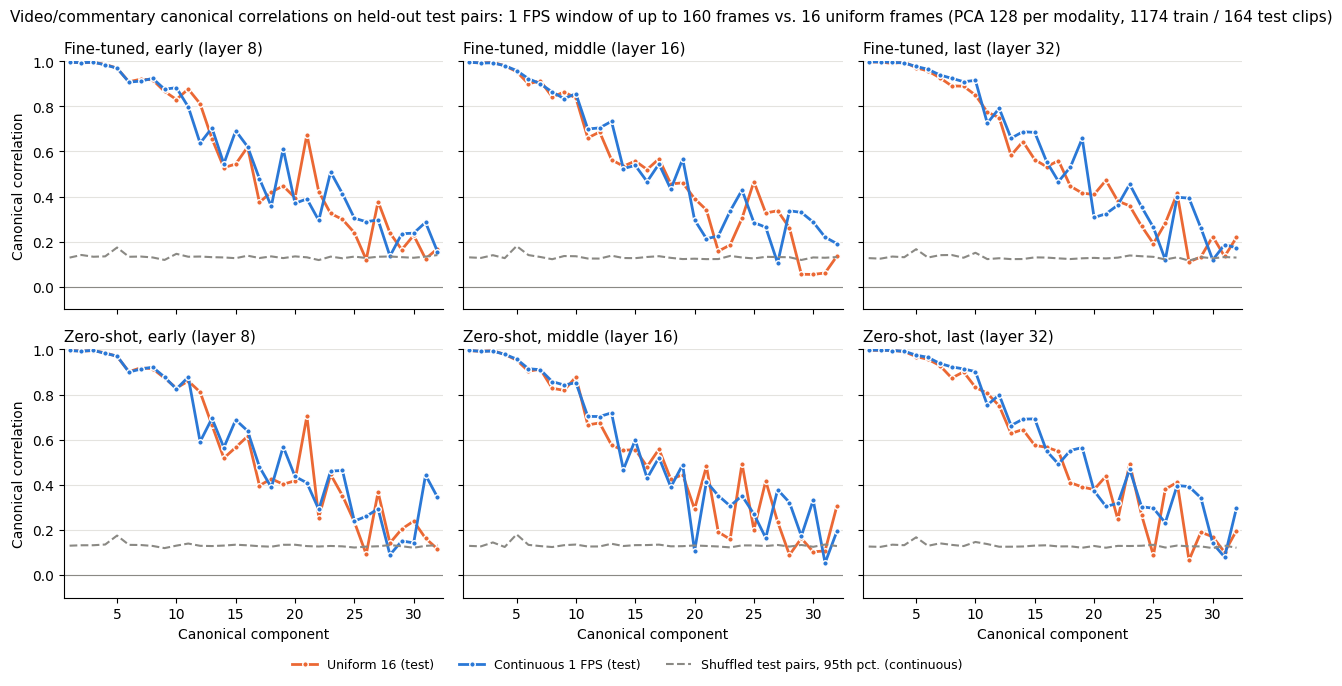

In [7]:
import matplotlib.pyplot as plt

# Held-out canonical correlations, continuous window vs. the midterm's uniform frames, per model and layer.
SAMPLING_COLORS = {"uniform": "#eb6834", "continuous": "#2a78d6"}
NULL_COLOR, GRID_COLOR = "#8a8984", "#e4e3df"
components = np.arange(1, N_COMPONENTS + 1)

fig, axes = plt.subplots(len(MODEL_NAMES), len(LAYERS), figsize=(4.2 * len(LAYERS), 3.3 * len(MODEL_NAMES)),
                         sharex=True, sharey=True)
for row, (model_name, model_label) in zip(axes, MODEL_NAMES.items()):
    for ax, (name, layer) in zip(row, LAYERS.items()):
        for sampling, sampling_label in SAMPLINGS.items():
            result = cca_results[sampling, model_name][name]
            ax.plot(components, result["test_corr"], color=SAMPLING_COLORS[sampling], lw=2, marker="o", ms=4,
                    markeredgecolor="white", markeredgewidth=1, label=f"{sampling_label} (test)")
        ax.plot(components, cca_results["continuous", model_name][name]["null_95"], color=NULL_COLOR, lw=1.5, ls="--",
                label="Shuffled test pairs, 95th pct. (continuous)")
        ax.axhline(0, color=NULL_COLOR, lw=0.8)
        ax.set_title(f"{model_label}, {name} (layer {layer})", loc="left", fontsize=11)
        ax.set_xlim(0.5, N_COMPONENTS + 0.5)
        ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    row[0].set_ylabel("Canonical correlation")
for ax in axes[-1]:
    ax.set_xlabel("Canonical component")
axes[0, 0].set_ylim(min(-0.1, min(r[name]["test_corr"].min() for r in cca_results.values() for name in LAYERS) - 0.05), 1.0)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"Video/commentary canonical correlations on held-out test pairs: {WINDOW_FPS} FPS window of up to "
             f"{MAX_FRAMES} frames vs. 16 uniform frames (PCA {PCA_DIMS} per modality, "
             f"{len(clips_by_split['train'])} train / {len(clips)} test clips)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig(f"figures/cca_canonical_correlations_continuous{WINDOW_FPS}fps{MAX_FRAMES}.png", dpi=200, bbox_inches="tight")
plt.show()

#### Shared vs. residual: linear probes for proficiency

The same probes as the midterm. Each train-mean-centered video embedding is split into its orthogonal
projection onto the 32-d CCA subspace (**shared**) and the rest (**residual**); the controls project onto the
PCA-128 space CCA works in (**PCA-128**), its top 32 components (**top-32 PCA**) and random 32-d subspaces of it
(**random**, mean of 10 draws). Logistic regression (regularization by 5-fold CV on train) is trained on the
train clips and scored on the test clips. Since window length now varies with clip duration, a probe on the
number of frames in the window alone is added to the scenario baselines.

In [8]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train_scores = np.array([clip["score"] for clip in clips_by_split["train"]])
test_scores = np.array([clip["score"] for clip in clips])

N_RANDOM_SUBSPACES = 10

def project(video, result, basis):
    """Train-mean-centered video embeddings projected onto the span of the orthonormal columns of basis."""
    return (video - result["mean"]) @ basis @ basis.T

def split_shared_residual(video, result):
    """(shared, residual) parts of video embeddings; shared + residual = video - train mean."""
    shared = project(video, result, result["basis"])
    return shared, video - result["mean"] - shared

def probe(train_x, test_x):
    """Test accuracy and balanced accuracy of a logistic-regression probe trained on the train clips."""
    model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
    model.fit(train_x, train_scores)
    pred = model.predict(test_x)
    return accuracy_score(test_scores, pred), balanced_accuracy_score(test_scores, pred)

majority = np.bincount(train_scores).argmax()  # train's most common level, predicted for every test clip
# Each test clip gets the most common train level of its own scenario (ties go to the lower level).
train_scenarios = np.array([clip["scenario"] for clip in clips_by_split["train"]])
scenario_majority = {s: np.bincount(train_scores[train_scenarios == s]).argmax() for s in np.unique(train_scenarios)}
scenario_majority_pred = np.array([scenario_majority[clip["scenario"]] for clip in clips])
scenario_encoder = OneHotEncoder(handle_unknown="ignore").fit([[clip["scenario"]] for clip in clips_by_split["train"]])
window_frames = {split: np.array([[continuous_raw[split][clip["take_name"]]["num_frames"]] for clip in clips_by_split[split]])
                 for split in ("train", "test")}
baselines = {
    "majority class": (accuracy_score(test_scores, np.full_like(test_scores, majority)),
                       balanced_accuracy_score(test_scores, np.full_like(test_scores, majority))),
    "per-scenario majority": (accuracy_score(test_scores, scenario_majority_pred),
                              balanced_accuracy_score(test_scores, scenario_majority_pred)),
    "scenario only": probe(scenario_encoder.transform([[clip["scenario"]] for clip in clips_by_split["train"]]).toarray(),
                           scenario_encoder.transform([[clip["scenario"]] for clip in clips]).toarray()),
    "window length only": probe(window_frames["train"], window_frames["test"]),
}

def probe_representation(raw_embeddings, cca_results):
    """Probe results at each layer for one model's video embeddings: the full embedding, its shared and residual
    parts, and the controls (the PCA-128 space CCA works in, its top 32 components, and random 32-d subspaces of
    it: mean and sd)."""
    train_video_all, video_all = raw_embeddings["train"][0], raw_embeddings["test"][0]
    results = {}
    for name, result in cca_results.items():
        layer = result["layer"]
        train_video = train_video_all[:, layer - 1].double().numpy()
        test_video = video_all[:, layer - 1].double().numpy()
        train_shared, train_residual = split_shared_residual(train_video, result)
        test_shared, test_residual = split_shared_residual(test_video, result)
        results[f"{name} (layer {layer}): full"] = probe(train_video - result["mean"], test_video - result["mean"])
        results[f"{name} (layer {layer}): shared"] = probe(train_shared, test_shared)
        results[f"{name} (layer {layer}): residual"] = probe(train_residual, test_residual)
        pca_basis = result["pca_video"].components_.T  # (2560, PCA_DIMS), orthonormal, by decreasing variance
        results[f"{name} (layer {layer}): pca128"] = probe(project(train_video, result, pca_basis),
                                                          project(test_video, result, pca_basis))
        results[f"{name} (layer {layer}): pca32"] = probe(project(train_video, result, pca_basis[:, :N_COMPONENTS]),
                                                         project(test_video, result, pca_basis[:, :N_COMPONENTS]))
        random_results = []
        for seed in range(N_RANDOM_SUBSPACES):
            # A random orthonormal 32-d basis of the PCA-128 space, the space CCA picks its directions from.
            rotation = np.linalg.qr(np.random.default_rng(seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
            basis = pca_basis @ rotation
            random_results.append(probe(project(train_video, result, basis), project(test_video, result, basis)))
        results[f"{name} (layer {layer}): random"] = tuple(np.mean(random_results, axis=0))
        results[f"{name} (layer {layer}): random sd"] = tuple(np.std(random_results, axis=0))
    return results

probe_results = {key: probe_representation(raw_embeddings[key], cca_results[key]) for key in raw_embeddings}

In [9]:
# Test accuracy (and balanced accuracy) for every sampling x model, then the accuracies as a LaTeX table
# (booktabs; best per column in bold).
PARTS = {"full": "Full", "shared": "Shared (CCA)", "residual": "Residual", "pca128": "PCA-128",
         "pca32": "Top-32 PCA", "random": "Random 32-d in PCA-128"}
rows = [(f"{name} (layer {layer}): {part}", layer, part) for name, layer in LAYERS.items() for part in PARTS]
columns = {(sampling, model_name): f"{SAMPLINGS[sampling]} {MODEL_NAMES[model_name]}"
           for sampling in SAMPLINGS for model_name in reversed(MODEL_NAMES)}

print(f"Proficiency probes on video embeddings ({len(train_scores)} train / {len(test_scores)} test clips): "
      f"accuracy / balanced accuracy\n")
print(f"{'features':<32}" + "".join(f"{label:>28}" for label in columns.values()))
for key, _, part in rows:
    print(f"{key:<32}" + "".join(f"{probe_results[c][key][0]:>20.3f} / {probe_results[c][key][1]:.3f}" for c in columns))
    if part == "random":
        print(f"{'  (sd over random subspaces)':<32}"
              + "".join(f"{probe_results[c][key + ' sd'][0]:>20.3f} / {probe_results[c][key + ' sd'][1]:.3f}" for c in columns))
print()
for baseline, (acc, balanced) in baselines.items():
    print(f"{baseline:<32}{acc:>20.3f} / {balanced:.3f}")
print(f"\nChance balanced accuracy: 0.250; one test clip = {1 / len(test_scores):.3f} accuracy")

best = {c: max(round(probe_results[c][key][0], 3) for key, _, _ in rows) for c in columns}

def cell(column, accuracy):
    return rf"\textbf{{{accuracy:.3f}}}" if round(accuracy, 3) == best[column] else f"{accuracy:.3f}"

latex = [
    r"\begin{table}[t]", r"\centering", r"\small",
    r"\caption{Test accuracy of logistic-regression probes predicting proficiency from Qwen3.5-4B video "
    rf"embeddings (mean-pooled over the video tokens after the given decoder layer), trained on the "
    rf"{len(train_scores):,} train takes and evaluated on the {len(test_scores)} test takes. Uniform: 16 frames "
    rf"spread over the whole clip, as in fine-tuning; continuous: a contiguous {WINDOW_FPS}~FPS window of up to "
    rf"{MAX_FRAMES} frames at a random start (the whole clip when shorter). Shared: projection onto the model's "
    r"32-dimensional video--commentary CCA subspace; residual: the remainder; full: the whole embedding; PCA-128: "
    r"projection onto the 128 leading principal components of the train embeddings, the space the CCA is fit in; "
    r"top-32 PCA: onto the 32 leading ones; random 32-d in PCA-128: onto a random 32-dimensional subspace of the "
    rf"PCA-128 space, averaged over {N_RANDOM_SUBSPACES} draws. Each model and sampling uses its own embeddings and subspaces.}}",
    r"\label{tab:continuous-probes}", r"\begin{tabular}{ll" + "c" * len(columns) + "}", r"\toprule",
    r" & & " + " & ".join(rf"\multicolumn{{2}}{{c}}{{{label}}}" for label in SAMPLINGS.values()) + r" \\",
    r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}",
    r"Layer & Representation & " + " & ".join(MODEL_NAMES[model_name] for _, model_name in columns) + r" \\", r"\midrule",
]
for k, (key, layer, part) in enumerate(rows):
    if part == "full" and k:
        latex.append(r"\midrule")
    latex.append(f"{layer if part == 'full' else ''} & {PARTS[part]} & "
                 + " & ".join(cell(c, probe_results[c][key][0]) for c in columns) + r" \\")
latex += [r"\midrule"] + [
    rf"{baseline.capitalize()} & & \multicolumn{{{len(columns)}}}{{c}}{{{baselines[baseline][0]:.3f}}} \\"
    for baseline in baselines if baseline != "scenario only"
] + [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print("\n" + "\n".join(latex))

Proficiency probes on video embeddings (1174 train / 164 test clips): accuracy / balanced accuracy

features                                Uniform 16 Zero-shot       Uniform 16 Fine-tuned  Continuous 1 FPS Zero-shot Continuous 1 FPS Fine-tuned
early (layer 8): full                          0.372 / 0.383               0.366 / 0.381               0.402 / 0.416               0.390 / 0.410
early (layer 8): shared                        0.402 / 0.389               0.384 / 0.374               0.427 / 0.415               0.409 / 0.359
early (layer 8): residual                      0.366 / 0.379               0.341 / 0.357               0.390 / 0.407               0.366 / 0.388
early (layer 8): pca128                        0.396 / 0.446               0.402 / 0.453               0.421 / 0.443               0.402 / 0.412
early (layer 8): pca32                         0.506 / 0.463               0.500 / 0.458               0.463 / 0.402               0.463 / 0.402
early (layer 8): random       